<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex05_%ED%99%9C%EC%84%B1%ED%99%94_%ED%95%A8%EC%88%98%2C_%EC%98%A4%EC%B0%A8_%EC%97%AD%EC%A0%84%EC%B0%A8%2C_%EA%B2%BD%EC%82%AC%ED%95%98%EA%B0%95%EB%B2%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 작업디렉토리 변경
%cd "/content/drive/MyDrive/Colab Notebooks/딥러닝 기초"

/content/drive/MyDrive/Colab Notebooks/딥러닝 기초


### 활성화 함수
- 초기 활성화 함수는 생물학적인 모방을 위해 구성 됨
  - Step function
- 계단 함수가 미분이 힘든 문제로 인해 유사한 활성화 함수인 Sig로 대체 됨
- 현재는 생물학적인 모방보다 인공신경망이 학습이 잘되는 형태의 활성화 함수를 사용

#### 활성화 함수 활용 case
- 중간층 : 학습을 잘 시키기 위한 용도
- 출력층 : 원하는 예측 형태를 만들기 위한 용도

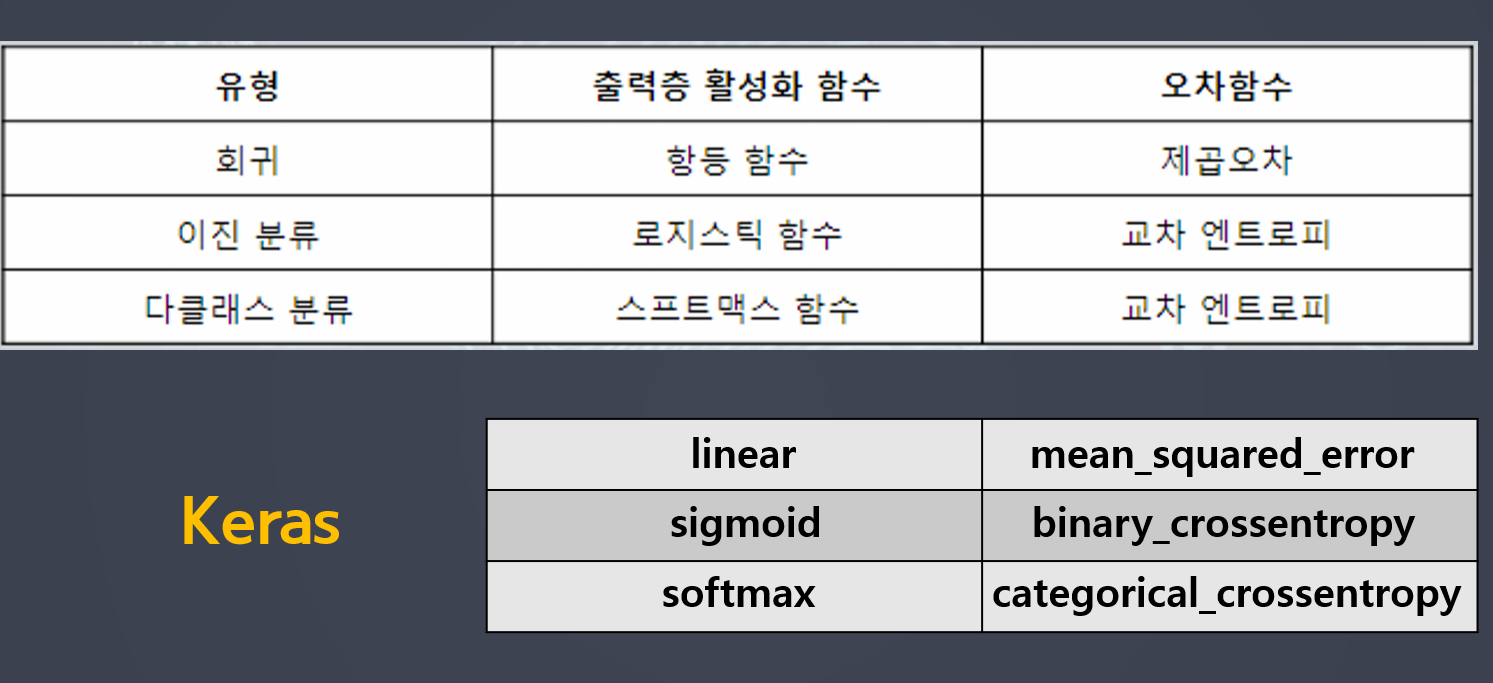

- 오차역전파 : error를 출력층에서 입력층으로 전달하면서 학습하는 과정
- 오차역전파 과정에서 중간층의 sigmoid가 미분되어 입력층으로 오차가 잘 전달되지 않는 현상 발생
(기울기 소실 문제)
- 중간층의 sigmoid를 변형하는 다양한 시도가 있었음
- 현재는 RELU가 기본 활성화 함수로 활용 됨

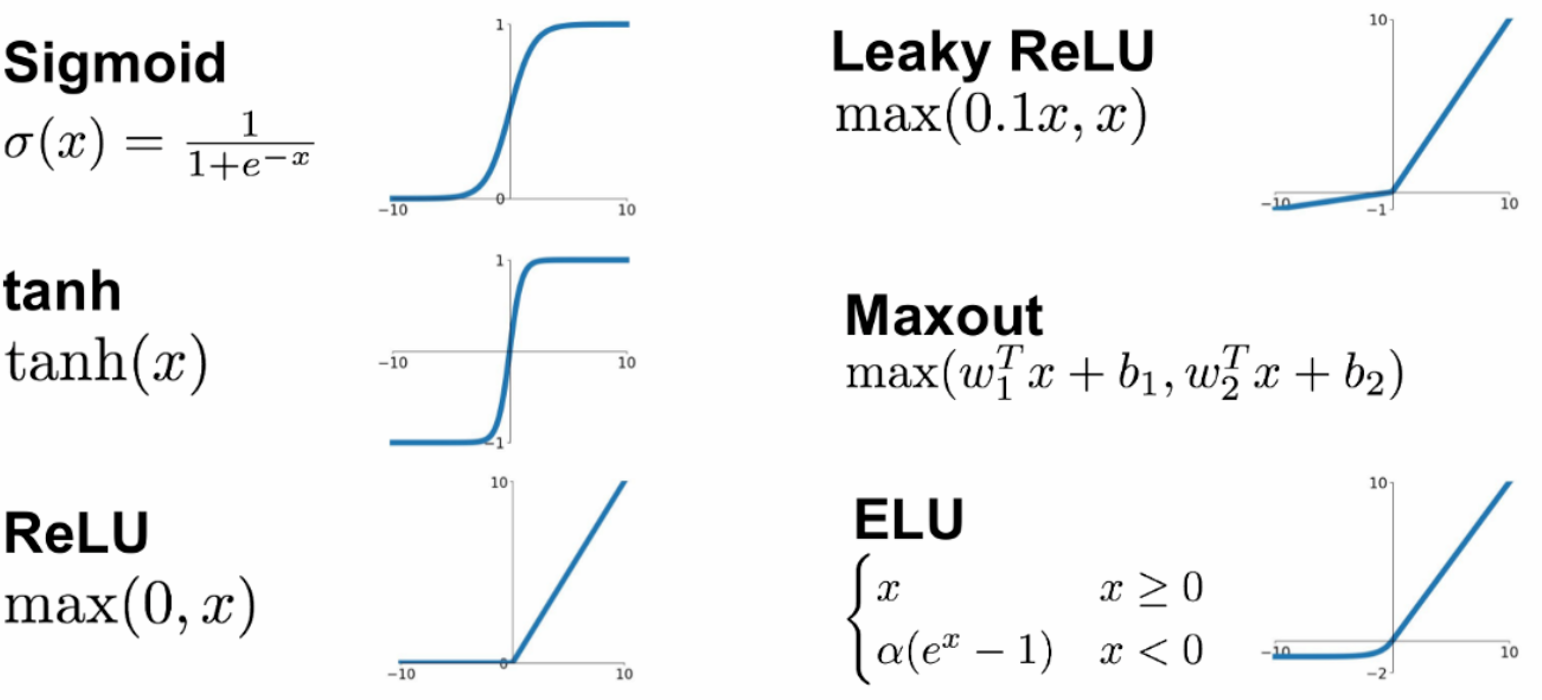

## 경사하강법 종류 이해
- 기울기 방향을 개선하는 방향
- 학습률 제어를 개선하는 방향
- 기울기 방향 + 학습률 제어 => Adam

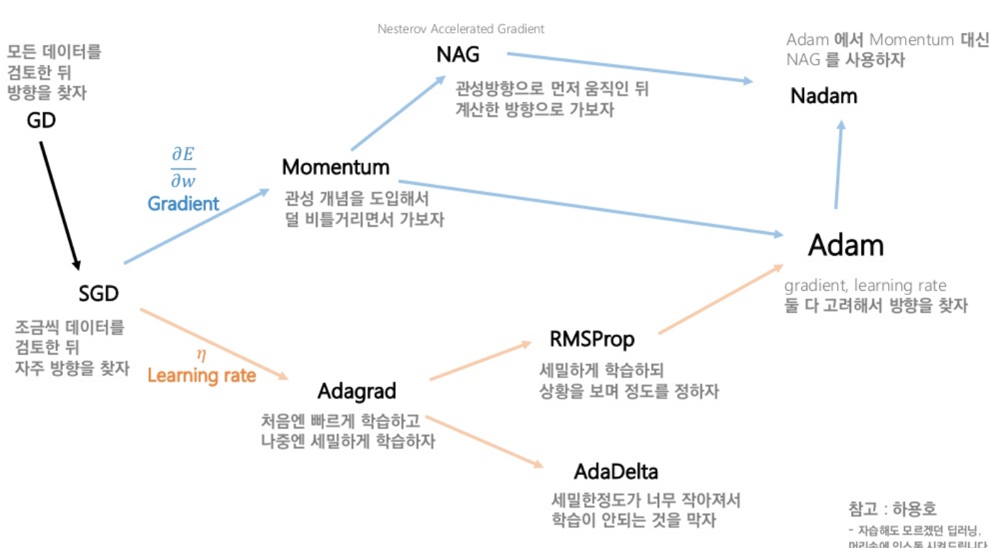

### 활성화 함수와 경사하강법 종류에 따른 비교 실습
- 활성화 함수 : sigmoid / 경사하강법 : SGD
- 활성화 함수 : ReLU / 경사하강법 : SGD
- 활성화 함수 : ReLU / 경사하강법 : Adam

In [ ]:
from tensorflow.keras import Sequential # 인공신경망 뼈대
from tensorflow.keras.layers import InputLayer # 입력층 레이어
from tensorflow.keras.layers import Flatten # 평탄화 레이어
from tensorflow.keras.layers import Dense # 퍼셉트론의 묶음을 표현하는 레이어
from tensorflow.keras.optimizers import SGD, Adam # 경사하강법 종류
from tensorflow.keras.layers import Conv2D, MaxPool2D # CNN관련 레이어

# 데이터로딩
import numpy as np
from tqdm import tqdm # 반복문 작업의 진척률을 시각화하는 도구
from tensorflow.keras.utils import image_dataset_from_directory # 폴더에서 이미지를 불러오는 도구
import matplotlib.pyplot as plt # 시각화 도구

In [ ]:
model1 = Sequential()
# 입력층
model1.add(InputLayer(shape=(224,224,3)))
# 중간층
model1.add(Conv2D(
           filters = 128,
           kernel_size = (3,3),
           activation = "relu"
           ))
model1.add(MaxPool2D())
model1.add(Flatten()) # 1차원으로 평탄화
model1.add(Dense(units = 128, activation='sigmoid'))
model1.add(Dense(units = 256, activation='sigmoid'))
model1.add(Dense(units = 512, activation='sigmoid'))
model1.add(Dense(units = 256, activation='sigmoid'))
# 출력층
model1.add(Dense(units = 5, activation='softmax'))
# 학습 및 평가방법 설정
model1.compile(optimizer=SGD(learning_rate=0.01),
              loss='sparse_categorical_crossentropy')

In [ ]:
model2 = Sequential()
# 입력층
model2.add(InputLayer(shape=(224,224,3)))
# 중간층
model2.add(Conv2D(
           filters = 128,
           kernel_size = (3,3),
           activation = "relu"
           ))
model2.add(MaxPool2D())
model2.add(Flatten()) # 1차원으로 평탄화
model2.add(Dense(units = 128, activation='relu'))
model2.add(Dense(units = 256, activation='relu'))
model2.add(Dense(units = 512, activation='relu'))
model2.add(Dense(units = 256, activation='relu'))
# 출력층
model2.add(Dense(units = 5, activation='softmax'))
# 학습 및 평가방법 설정
model2.compile(optimizer=SGD(learning_rate=0.01),
               loss='sparse_categorical_crossentropy')

In [ ]:
model3 = Sequential()
# 입력층
model3.add(InputLayer(shape=(224,224,3)))
# 중간층
model3.add(Conv2D(
           filters = 128,
           kernel_size = (3,3),
           activation = "relu"
           ))
model3.add(MaxPool2D())
model3.add(Flatten()) # 1차원으로 평탄화
model3.add(Dense(units = 128, activation='relu'))
model3.add(Dense(units = 256, activation='relu'))
model3.add(Dense(units = 512, activation='relu'))
model3.add(Dense(units = 256, activation='relu'))
# 출력층
model3.add(Dense(units = 5, activation='softmax'))
# 학습 및 평가방법 설정
model3.compile(optimizer=Adam(learning_rate=0.001),
               loss='sparse_categorical_crossentropy')

#### 테스트 데이터 500개 로드
- 8:2의 비율로 분할하여 학습/검증 데이터로 활용

In [ ]:
# 폴더에서 이미지데이터 정보 불러오기
train_data = image_dataset_from_directory(
    directory = "./data/animal_test", # 읽어들일 경로
    labels='inferred', # 폴더명을 인식해서 정답으로 지정
    label_mode='int', # 정답을 지정된 숫자 형식으로 변환
    color_mode='rgb', # 이미지를 컬러 채널로 로딩
    batch_size=32, # 한번에 처리하는 데이터 수 (메모리 관련)
    image_size=(224, 224) # 이미지 리사이징 크기 (서로 다른 크기의 이미지를 통일)
)

Found 500 files belonging to 5 classes.


In [ ]:
# 훈련용 데이터가 저장될 리스트 생성
X_train = []
y_train = []

In [ ]:
# 반복문을 이용해서 데이터 (사진, 정답라벨) 읽기
for img, label in tqdm(train_data.as_numpy_iterator()) :
  X_train.append(img) # 32개씩 이미지 묶음을 리스트에 저장
  y_train.append(label) # 32개씩 정답 묶음을 리스트에 저장

16it [02:05,  7.84s/it]


In [ ]:
# 32개씩 묶은 넘파이 배열을 하나로 통합
X_train_final = np.concat(X_train)
y_train_final = np.concat(y_train)

In [ ]:
X_train_final.shape, y_train_final.shape

((500, 224, 224, 3), (500,))

In [ ]:

h1 = model1.fit(X_train_final, y_train_final, epochs=10, validation_split=0.2, verbose=0)
h2 = model2.fit(X_train_final, y_train_final, epochs=10, validation_split=0.2, verbose=0)
h3 = model3.fit(X_train_final, y_train_final, epochs=10, validation_split=0.2, verbose=0)

### 시각화

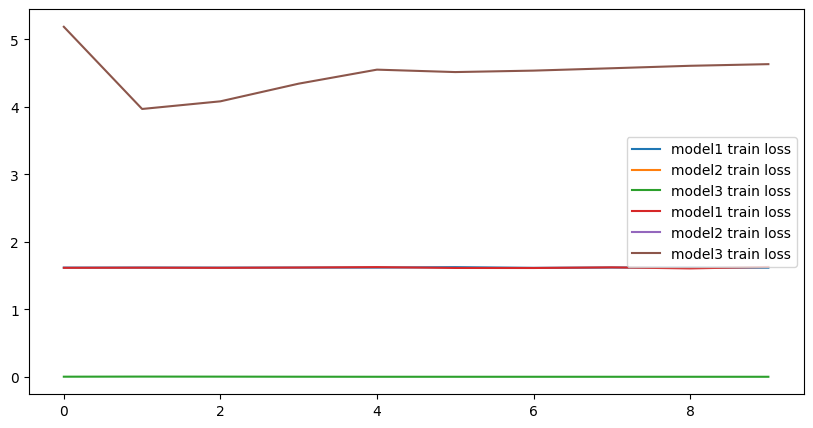

In [ ]:
plt.figure(figsize=(10,5))
# 훈련데이터에 대한 loss
plt.plot(h1.history['loss'], label='model1 train loss')
plt.plot(h2.history['loss'], label='model2 train loss')
plt.plot(h3.history['loss'], label='model3 train loss')
# 검증데이터에 대한 loss
plt.plot(h1.history['val_loss'], label='model1 train loss')
plt.plot(h2.history['val_loss'], label='model2 train loss')
plt.plot(h3.history['val_loss'], label='model3 train loss')
plt.legend() # 범례
plt.show()

In [ ]:
h1.history['loss']

In [ ]:
h2.history['loss']

In [ ]:
h3.history['val_loss']